# Alpha X Oct-Nov 2026 - QQQ hourly dip-buy: final research notebook (v4, as of 17 Nov 2026)
**Group 6, Malaysia.** Two candidates are submitted side by side, with the full record of every test:

| | Candidate | Status |
|---|---|---|
| **C1** (lead) | QQQ, N=7 bars, k=1.2%, VIX/VIX3M(prev session) < 1 gate, **F3 news-day filter**, **hold 35 bars**, 3% stop | **Exploratory and marginal.** Designed after the final window had been seen (second-use window). Pre-registered v4 label: SUPPORTED, but only just. |
| **F3** (earlier pick) | Same rule, **hold 21 bars** | Passed IS and Selection, **failed the 2020-2023 older-history test and lost 2.6% in the final out-of-sample window**. |

Rules that never changed: USD 100,000 fixed unit per entry, no compounding, 0.10% per side (2x = 0.20%), signal at the close of bar t, fill at the OPEN of bar t+1, 1h regular-hours IBKR bars, previous-session (lagged) VIX/VIX3M gate, forced exit at the end of a window.

**How to read this notebook.** It does not re-run any run-once study. It (1) verifies the fingerprints of the pre-registrations and code, (2) reads the stored results of every stage, (3) recomputes the headline numbers from the stored daily PnL and trade ledgers, (4) re-derives the C1 / F3 / DIA full-span PnL with the frozen engine as an independent reproduction check (a re-run for reproduction, not a new test), and (5) states the weaknesses. Run it from `60_submission/` (it uses `Path.cwd().parent` as the project root).

In [1]:
import sys, re, hashlib, io, contextlib, json
from pathlib import Path
from statistics import NormalDist
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
ROOT = Path.cwd().parent; sys.path.insert(0, str(ROOT / "20_src"))
import alphax_engine_v2 as E
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
print("project root:", ROOT.name, "| engine sha256:", sha(ROOT / "20_src/alphax_engine_v2.py")[:16], "...")

project root: proj | engine sha256: 1980e11e5e475b17 ...


## 1. Fingerprint check: were the rules and code edited after the results were seen?
Every study was written down and hashed (SHA-256) before it ran; the stored hashes are in `90_logs/*.sha256`. `OK` = the file today matches the hash stored before the run. `not present here` = that file is not in this copy of the folder (it is on the research machine).

In [2]:
def logged(p):
    t = Path(p).read_text(errors="ignore")
    out = re.findall(r"^\s*([0-9a-fA-F]{64})\s+\*?(\S+)", t, re.M)
    out += re.findall(r"Hash\s*:\s*([0-9a-fA-F]{64})\s*\r?\nPath\s*:\s*(\S[^\r\n]*)", t)
    return [(h.lower(), q.strip()) for h, q in out]
def locate(name):
    base = Path(name.replace("\\", "/")).name
    for pat in (f"*/{base}", f"10_data/*/{base}", f"10_data/{base}"):
        for p in ROOT.glob(pat): return p
rows = []
for log in sorted((ROOT / "90_logs").glob("*.sha256")):
    for h, n in logged(log):
        f = locate(n); rows.append(dict(stored_in=log.name, file=Path(n.replace("\\", "/")).name, hash_first12=h[:12], status="not present here" if f is None else ("OK" if sha(f) == h else "MISMATCH")))
INT = pd.DataFrame(rows); print(INT["status"].value_counts().to_dict()); display(INT)
assert not (INT["status"] == "MISMATCH").any(), "a file differs from its stored hash"
print("\nRun-once locks (each study refuses to run twice):")
for l in sorted((ROOT / "90_logs").glob("*.lock")): print(" ", l.name, "->", l.read_text().strip())
for f in ("dia_data_check.txt", "hourly_data_check_oos.txt"): print(f, "->", "ALL PASS" if "ALL PASS" in (ROOT / "90_logs" / f).read_text() else "CHECK")

{'OK': 23, 'not present here': 2}


,stored_in,file,hash_first12,status
0,FROZEN_CONFIG_OOS.sha256,FROZEN_CONFIG_OOS.json,c3d4bd2ed3d8,OK
1,PRE_REGISTRATION_v1.sha256,PRE_REGISTRATION_v1.md,7f02cd459c18,OK
2,PRE_REGISTRATION_v2.sha256,PRE_REGISTRATION_v2.md,776d4321a5b6,OK
3,PRE_REGISTRATION_v2_1.sha256,PRE_REGISTRATION_v2_1_PREWINDOW.md,a97d0d2199a4,OK
4,PRE_REGISTRATION_v3.sha256,PRE_REGISTRATION_v3_PROFILE_TREND.md,b02fc3737705,OK
5,PRE_REGISTRATION_v4.sha256,PRE_REGISTRATION_v4_NEW_CANDIDATES.md,159ff438a3ea,OK
6,data_freeze_20261113.sha256,QQQ_1h_RTH.csv,e07181eaa5e6,OK
7,data_freeze_20261113.sha256,IWM_1h_RTH.csv,bad1a3967f6f,not present here
8,engine_v1.sha256,alphax_engine.py,9891a46fa252,OK
9,engine_v1.sha256,selftest_synthetic.py,e63899578b5c,not present here



Run-once locks (each study refuses to run twice):
  OOS_RUN.lock -> run 2026-11-17T14:16:12.394416 window 2025-12-01..2026-11-12
  PREWINDOW_RUN.lock -> run 2026-11-15T16:59:23.760389 window 2020-01-03..2023-11-10
  V3_RUN.lock -> run 2026-11-16T01:28:19.007446
  V4_RUN.lock -> run 2026-11-17T15:34:52.234748
dia_data_check.txt -> ALL PASS
hourly_data_check_oos.txt -> ALL PASS


## 2. The record, stage by stage
F3 is the frozen v2 pick. Stored results come from separate runs (v2.1 older history, final window, v4), so the first cell also cross-checks that the runs agree with each other.

In [3]:
R4 = pd.read_csv(ROOT / "40_results/V4_results.csv"); V4V = pd.read_csv(ROOT / "40_results/V4_verdicts.csv")
BLK = {"PRE": "2020-01 to 2023-11 (older history)", "IS": "In-sample 2023-11 to 2025-06", "SEL": "Selection 2025-07 to 2025-11", "FINAL": "Final window 2025-12 to 2026-11", "FULL": "Full span 2020-01 to 2026-11"}
cols = ["trades", "sharpe", "net_pct", "net_pct_2x_cost", "max_dd_pct", "win_rate", "profit_factor", "top3_share"]
def tab(variant): t = R4[R4.variant == variant].set_index("block").loc[list(BLK)]; t.index = [BLK[b] for b in t.index]; return t[[c for c in cols if c in t.columns]].round(3)
for v in ("C1_QQQ_H35_F3", "QQQ_F3_H21_ref", "QQQ_base_H21_ref", "buy_and_hold_QQQ"):
    print("\n==", v); display(tab(v))
# cross-run consistency: v4 reference rows must equal the separately stored earlier runs
pre = pd.read_csv(ROOT / "40_results/PRE_results_v21.csv"); oos = pd.read_csv(ROOT / "40_results/OOS_results.csv")
f3_pre = pre[pre["variant"].str.contains("F3")].iloc[0]; f3_oos = oos[oos["variant"].str.contains("F3")].iloc[0]
a = R4[(R4.variant == "QQQ_F3_H21_ref") & (R4.block == "PRE")].iloc[0]; b = R4[(R4.variant == "QQQ_F3_H21_ref") & (R4.block == "FINAL")].iloc[0]
print("\nF3 older history: v2.1 run Sharpe %.4f vs v4 reference %.4f | final window: OOS run %.4f vs v4 reference %.4f" % (f3_pre.sharpe, a.sharpe, f3_oos.sharpe, b.sharpe))
assert abs(f3_pre.sharpe - a.sharpe) < 1e-9 and abs(f3_oos.sharpe - b.sharpe) < 1e-9 and f3_pre.trades == a.trades and f3_oos.trades == b.trades


== C1_QQQ_H35_F3


,trades,sharpe,net_pct,net_pct_2x_cost,max_dd_pct,win_rate,profit_factor,top3_share
2020-01 to 2023-11 (older history),128,0.471,35.788,10.126,-29.154,0.555,1.221,0.606
In-sample 2023-11 to 2025-06,40,0.821,17.490,9.465,-13.876,0.625,1.440,0.826
Selection 2025-07 to 2025-11,9,1.259,5.900,4.093,-5.559,0.556,1.974,1.769
Final window 2025-12 to 2026-11,32,0.182,3.188,-3.222,-14.314,0.562,1.080,5.805
Full span 2020-01 to 2026-11,209,0.514,62.366,20.462,-29.154,0.569,1.252,0.368



== QQQ_F3_H21_ref


,trades,sharpe,net_pct,net_pct_2x_cost,max_dd_pct,win_rate,profit_factor,top3_share
2020-01 to 2023-11 (older history),157,0.162,11.078,-20.365,-45.117,0.548,1.066,2.033
In-sample 2023-11 to 2025-06,51,1.094,20.769,10.538,-6.014,0.627,1.611,0.594
Selection 2025-07 to 2025-11,10,2.301,9.873,7.861,-3.017,0.800,4.004,1.033
Final window 2025-12 to 2026-11,39,-0.185,-2.559,-10.364,-10.812,0.513,0.915,NaN
Full span 2020-01 to 2026-11,257,0.365,39.160,-12.330,-45.117,0.568,1.167,0.575



== QQQ_base_H21_ref


,trades,sharpe,net_pct,net_pct_2x_cost,max_dd_pct,win_rate,profit_factor,top3_share
2020-01 to 2023-11 (older history),164,-0.121,-8.574,-41.399,-52.873,0.524,0.955,NaN
In-sample 2023-11 to 2025-06,52,0.837,16.080,5.653,-11.390,0.635,1.438,0.752
Selection 2025-07 to 2025-11,10,0.681,2.879,0.874,-5.811,0.700,1.529,2.293
Final window 2025-12 to 2026-11,41,-0.395,-5.692,-13.894,-15.489,0.512,0.839,NaN
Full span 2020-01 to 2026-11,267,0.042,4.693,-48.765,-52.873,0.551,1.017,4.799



== buy_and_hold_QQQ


,trades,sharpe,net_pct,net_pct_2x_cost,max_dd_pct,win_rate,profit_factor,top3_share
2020-01 to 2023-11 (older history),0,0.545,77.121,NaN,-35.653,NaN,NaN,NaN
In-sample 2023-11 to 2025-06,0,1.064,46.161,NaN,-22.873,NaN,NaN,NaN
Selection 2025-07 to 2025-11,0,1.795,12.423,NaN,-7.902,NaN,NaN,NaN
Final window 2025-12 to 2026-11,0,0.529,11.944,NaN,-14.739,NaN,NaN,NaN
Full span 2020-01 to 2026-11,0,0.718,222.222,NaN,-35.653,NaN,NaN,NaN



F3 older history: v2.1 run Sharpe 0.1621 vs v4 reference 0.1621 | final window: OOS run -0.1846 vs v4 reference -0.1846


### What each pre-registered stage concluded (typed from the stored result files above and in `40_results/`)

| Study | Date | Verdict |
|---|---|---|
| v1: 12-config grid on IN-SAMPLE, then SELECTION | 13 Nov | Picked N=7, k=1.2%, H=21. Base passed IS and Selection. |
| v2: four Flywheel filters on the base | 13-14 Nov | F3 (skip days with Fed decision / jobs report / CPI) was the only one eligible; chosen. |
| v2.1: older history 2020-Nov 2023, run once | 15 Nov | **Base NOT supported** (Sharpe -0.12, -41.4% at 2x cost). **F3 did not rescue it** (Sharpe 0.16, -20.4% at 2x cost). |
| v3: profile filters P1/P2, trend guard T1, C1(v3) | 16 Nov | **All failed the IS bar** (Sharpe 0.76 / 0.84 / 0.49 / 0.77 vs 0.94 needed). Nothing eligible. |
| Final window, F3 frozen, run once | 17 Nov | **F3 lost 2.6%** (Sharpe -0.19, -10.4% at 2x cost). Base lost 5.7%. Buy-and-hold QQQ +11.9%. |
| v4: C1 (QQQ H35 + F3) and C2 (DIA + F3), run once on all blocks | 17 Nov | **C1 SUPPORTED (marginal). C2 NOT SUPPORTED.** Exploratory: second-use window. |


In [4]:
display(V4V)

,candidate,standard_checks_and_3_of_4_blocks_positive,blocks_positive_of_4,extra_condition,extra_met,LABEL
0,C1_QQQ_H35_F3,True,4,beats QQQ F3 H21 by Sharpe +0.10 and drawdown no worse,True,SUPPORTED
1,C2_DIA_F3,False,3,news-day filter helps on DIA (Sharpe +0.10 over DIA base),False,NOT SUPPORTED


## 3. Recompute the headline numbers independently from the stored ledgers
The full-span numbers are rebuilt here from `V4_daily_pnl_full.csv` and `V4_trades.csv` and must tie to `V4_results.csv`.

In [5]:
D = pd.read_csv(ROOT / "40_results/V4_daily_pnl_full.csv", index_col=0); D.index = pd.to_datetime(D.index)
TR = pd.read_csv(ROOT / "40_results/V4_trades.csv", parse_dates=["signal_time", "entry_time", "exit_time"])
def full_metrics(d):
    r = d / E.CAPITAL; eq = E.CAPITAL + d.cumsum()
    return dict(sharpe=np.sqrt(252) * r.mean() / r.std(ddof=1), net_pct=d.sum() / E.CAPITAL * 100, max_dd_pct=((eq - eq.cummax()) / eq.cummax()).min() * 100)
chk = []
for v in ("C1_QQQ_H35_F3", "QQQ_F3_H21_ref", "QQQ_base_H21_ref", "C2_DIA_F3", "C2b_DIA_base"):
    m = full_metrics(D[v]); s = R4[(R4.variant == v) & (R4.block == "FULL")].iloc[0]; t = TR[(TR.variant == v) & (TR.block == "FULL")]
    ok = abs(m["sharpe"] - s.sharpe) < 1e-9 and abs(m["net_pct"] - s.net_pct) < 1e-9 and abs(m["max_dd_pct"] - s.max_dd_pct) < 1e-9 and len(t) == s.trades and abs(t.pnl_usd.sum() / E.CAPITAL * 100 - s.net_pct) < 1e-6
    chk.append(dict(variant=v, sharpe=round(m["sharpe"], 4), net_pct=round(m["net_pct"], 3), max_dd_pct=round(m["max_dd_pct"], 2), trades_in_ledger=len(t), ties_to_results=ok))
CHK = pd.DataFrame(chk); display(CHK); assert CHK.ties_to_results.all()

,variant,sharpe,net_pct,max_dd_pct,trades_in_ledger,ties_to_results
0,C1_QQQ_H35_F3,0.5139,62.366,-29.15,209,True
1,QQQ_F3_H21_ref,0.3653,39.160,-45.12,257,True
2,QQQ_base_H21_ref,0.0425,4.693,-52.87,267,True
3,C2_DIA_F3,0.3695,22.347,-12.35,151,True
4,C2b_DIA_base,0.3151,20.498,-17.80,163,True


## 4. Independent reproduction with the frozen engine (a re-run for reproduction, not a new test)
This re-derives the full-span daily PnL of C1, F3 and the DIA variants from the price files, VIX/VIX3M and the frozen F3 event rules, and compares with the stored ledger. It needs the data files; if they are absent the cell says so.

In [6]:
CFG = json.loads((ROOT / "00_rules/FROZEN_CONFIG_OOS.json").read_text(encoding="utf-8"))
EVENT_RULES = [("eq" if k == "equals" else "sw", s) for k, s in CFG["F3_event_rules"]]; HAND = {pd.Timestamp(x["date"]) for x in CFG["hand_added_event_days_et"]}
need = [ROOT / "10_data/ibkr_hourly_merged/QQQ_1h_RTH_merged.csv", ROOT / "10_data/ibkr_hourly_dia/DIA_1h_RTH.csv", ROOT / "10_data/r2_snapshot/market_data/daily/_VIX.csv", ROOT / "10_data/r2_snapshot/market_data/daily/_VIX3M.csv", ROOT / "10_data/r2_snapshot/news/economic_calendar.csv"]
REPRO = None
if all(p.exists() for p in need):
    END = "2026-11-12"; START = "2020-01-03"
    ratio = E.load_gate(need[2], need[3]); cal = pd.read_csv(need[4], usecols=["date", "country", "event"], low_memory=False)
    cal = cal[cal["country"] == "US"].copy(); cal["dt"] = pd.to_datetime(cal["date"]).dt.tz_localize("UTC").dt.tz_convert("America/New_York"); cal["day"] = cal["dt"].dt.tz_localize(None).dt.normalize(); cal = cal[cal["day"] <= pd.Timestamp(END)]
    mm = np.zeros(len(cal), bool)
    for kind, s in EVENT_RULES: mm |= (cal["event"] == s).values if kind == "eq" else cal["event"].str.startswith(s).values
    ev = set(cal.loc[mm, "day"]) | {h for h in HAND if h <= pd.Timestamp(END)}
    def f3_mask(bars):
        d_arr = bars["day"].values; entry_day = np.where(np.append(d_arr[1:] != d_arr[:-1], True), np.append(d_arr[1:], d_arr[-1]), d_arr)
        return np.array([pd.Timestamp(x) not in ev for x in entry_day])
    out = []
    for name, f, H, useF3 in (("QQQ_F3_H21_ref", need[0], 21, True), ("QQQ_base_H21_ref", need[0], 21, False), ("C1_QQQ_H35_F3", need[0], 35, True), ("C2_DIA_F3", need[1], 21, True), ("C2b_DIA_base", need[1], 21, False)):
        bars = E.load_bars(f, END); T, d, _ = E.backtest(bars, ratio, 7, 0.012, H, START, extra_ok=f3_mask(bars) if useF3 else None)
        s = D[name].reindex(d.index).fillna(0.0); diff = float((d.values - s.values).max() if len(s) else 0.0); diff = float(np.abs(d.values - s.values).max())
        out.append(dict(variant=name, trades_rerun=len(T), trades_stored=int(((TR.variant == name) & (TR.block == "FULL")).sum()), max_abs_daily_pnl_diff_usd=diff, reproduced=bool(diff < 1e-6 and len(T) == int(((TR.variant == name) & (TR.block == "FULL")).sum()))))
    REPRO = pd.DataFrame(out); display(REPRO); assert REPRO.reproduced.all()
else:
    print("price / VIX / calendar files are not in this copy of the folder: reproduction cell skipped (run it on the research machine).")

,variant,trades_rerun,trades_stored,max_abs_daily_pnl_diff_usd,reproduced
0,QQQ_F3_H21_ref,257,257,4.547474e-13,True
1,QQQ_base_H21_ref,267,267,4.547474e-13,True
2,C1_QQQ_H35_F3,209,209,4.547474e-13,True
3,C2_DIA_F3,151,151,4.547474e-13,True
4,C2b_DIA_base,163,163,4.547474e-13,True


## 5. Equity curves, drawdowns and calendar years (full span 3 Jan 2020 to 12 Nov 2026)
Cumulative net profit as % of one USD 100k unit. Buy-and-hold = USD 100k of QQQ bought on the first day. C1 was designed after the final window was seen.

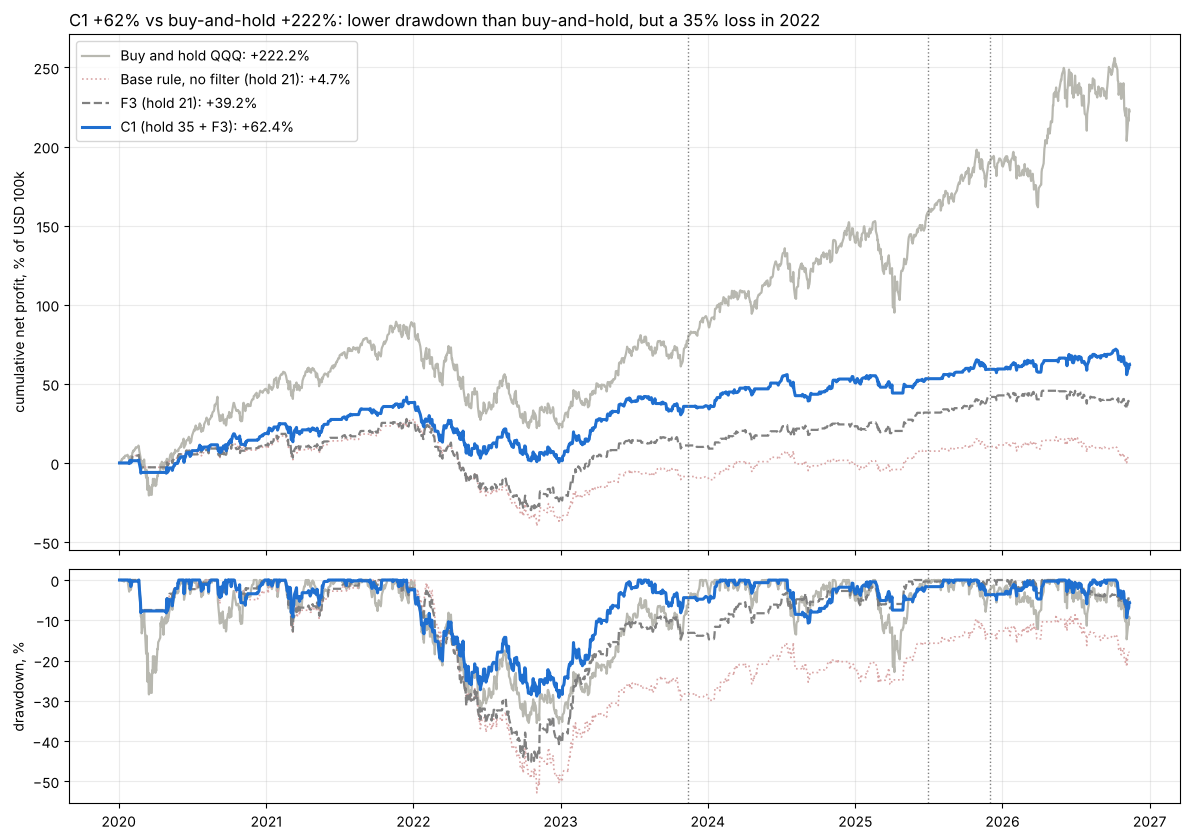

,C1 (H35+F3),F3 (H21),Base (H21),Buy and hold QQQ
2020,18.6,11.2,10.2,46.9
2021,19.6,14.1,17.2,39.4
2022,-35.4,-47.2,-61.8,-61.5
2023,33.3,32.8,25.7,67.1
2024,14.7,12.1,7.4,47.7
2025,8.7,19.7,12.7,48.3
2026,3.0,-3.6,-6.7,34.3


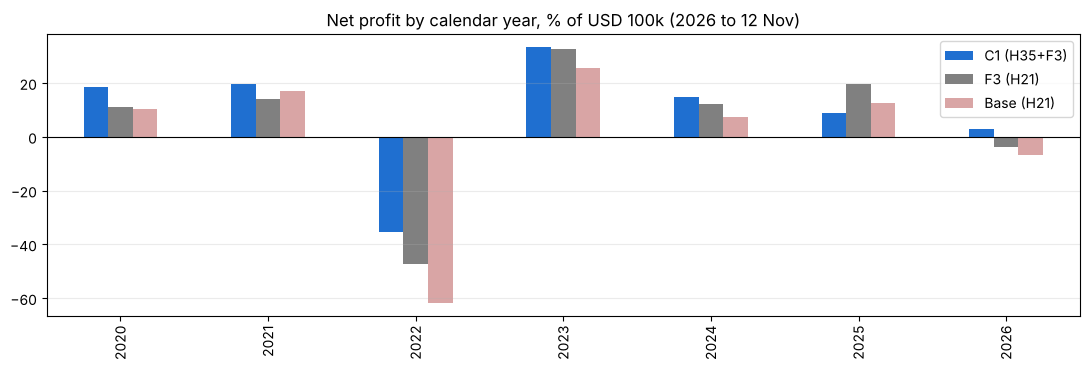

In [7]:
eq = D.cumsum() / E.CAPITAL * 100; ddown = ((E.CAPITAL + D.cumsum()) / (E.CAPITAL + D.cumsum()).cummax() - 1) * 100
fig, ax = plt.subplots(2, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for v, lab, st in (("buy_and_hold_QQQ", "Buy and hold QQQ", dict(color="#b8b8b0", lw=1.6)), ("QQQ_base_H21_ref", "Base rule, no filter (hold 21)", dict(color="#d9a5a5", lw=1.2, ls=":")), ("QQQ_F3_H21_ref", "F3 (hold 21)", dict(color="#808080", lw=1.6, ls="--")), ("C1_QQQ_H35_F3", "C1 (hold 35 + F3)", dict(color="#1f6fd0", lw=2.2))):
    ax[0].plot(eq.index, eq[v], label=f"{lab}: {eq[v].iloc[-1]:+.1f}%", **st); ax[1].plot(ddown.index, ddown[v], **st)
for a_ in ax:
    for d_, t_ in (("2023-11-13", "IS starts"), ("2025-07-01", "Selection"), ("2025-12-01", "Final window")): a_.axvline(pd.Timestamp(d_), color="grey", ls=":", lw=1)
ax[0].set_ylabel("cumulative net profit, % of USD 100k"); ax[1].set_ylabel("drawdown, %"); ax[0].legend(loc="upper left"); ax[0].grid(alpha=.25); ax[1].grid(alpha=.25)
ax[0].set_title("C1 +62% vs buy-and-hold +222%: lower drawdown than buy-and-hold, but a 35% loss in 2022", loc="left"); plt.tight_layout(); plt.show()
yr = (D[["C1_QQQ_H35_F3", "QQQ_F3_H21_ref", "QQQ_base_H21_ref", "buy_and_hold_QQQ"]].groupby(D.index.year).sum() / E.CAPITAL * 100).round(1)
yr.columns = ["C1 (H35+F3)", "F3 (H21)", "Base (H21)", "Buy and hold QQQ"]; display(yr)
yr.iloc[:, :3].plot.bar(figsize=(11, 3.8), color=["#1f6fd0", "#808080", "#d9a5a5"], title="Net profit by calendar year, % of USD 100k (2026 to 12 Nov)"); plt.axhline(0, color="k", lw=.8); plt.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

## 6. Block-by-block view, including 2x cost
C1 is positive in all four blocks at normal cost, but at 2x cost the final-window block turns negative.

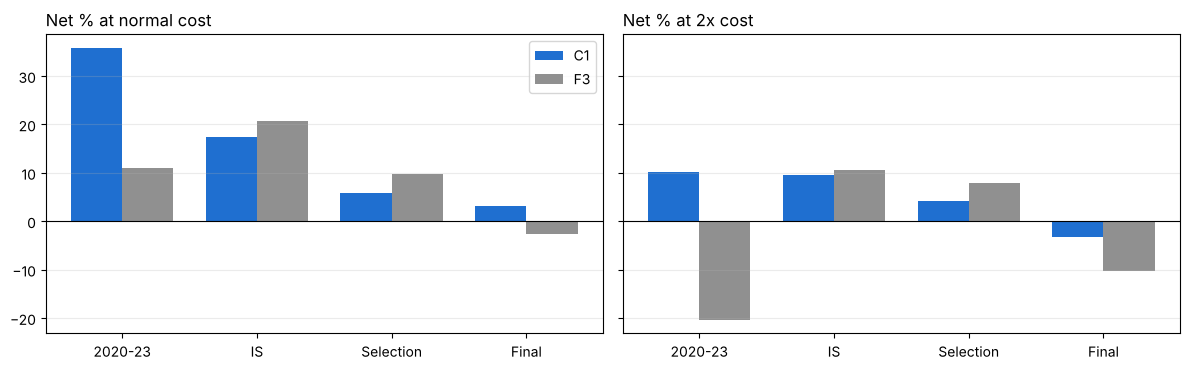

,C1 Sharpe,F3 Sharpe,C1 trades,C1 top-3 share of profit,C1 profit without top 3 (USD)
2020-23,0.47,0.16,128.0,0.61,14113.49
IS,0.82,1.09,40.0,0.83,3039.40
Selection,1.26,2.30,9.0,1.77,-4536.65
Final,0.18,-0.18,32.0,5.80,-15316.37


In [8]:
bl = ["PRE", "IS", "SEL", "FINAL"]; lab = ["2020-23", "IS", "Selection", "Final"]
g = lambda v, c: [float(R4[(R4.variant == v) & (R4.block == b)][c].iloc[0]) for b in bl]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True); x = np.arange(4); w = .38
for ax_, c, t in ((axs[0], "net_pct", "Net % at normal cost"), (axs[1], "net_pct_2x_cost", "Net % at 2x cost")):
    ax_.bar(x - w/2, g("C1_QQQ_H35_F3", c), w, label="C1", color="#1f6fd0"); ax_.bar(x + w/2, g("QQQ_F3_H21_ref", c), w, label="F3", color="#909090")
    ax_.set_xticks(x); ax_.set_xticklabels(lab); ax_.axhline(0, color="k", lw=.8); ax_.set_title(t, loc="left"); ax_.grid(axis="y", alpha=.25)
axs[0].legend(); plt.tight_layout(); plt.show()
sh = pd.DataFrame({"C1 Sharpe": g("C1_QQQ_H35_F3", "sharpe"), "F3 Sharpe": g("QQQ_F3_H21_ref", "sharpe"), "C1 trades": g("C1_QQQ_H35_F3", "trades"), "C1 top-3 share of profit": g("C1_QQQ_H35_F3", "top3_share"), "C1 profit without top 3 (USD)": g("C1_QQQ_H35_F3", "pnl_ex_top3")}, index=lab).round(2); display(sh)

## 7. How strong is the evidence? (approximate, and deliberately unflattering)
* **t-statistic** of the daily-PnL Sharpe, and the one-sided p-value.
* **Deflated Sharpe (approximate)**: the chance the full-span Sharpe beats what the best of N tried configurations would reach by luck. It needs an assumption about how spread out the tried Sharpes are, so it is shown for a range. N = distinct configurations in `config_counter.csv`.

In [9]:
ND = NormalDist(); g_ = 0.5772156649
def e_max(n): return (1 - g_) * ND.inv_cdf(1 - 1 / n) + g_ * ND.inv_cdf(1 - 1 / (n * np.e))
cc = pd.read_csv(ROOT / "90_logs/config_counter.csv"); N_TRIALS = cc["config_id"].nunique(); print("distinct configurations tried:", N_TRIALS, "| counter rows:", len(cc))
is12 = pd.read_csv(ROOT / "40_results/IS_results_v1_QQQ.csv")["sharpe"]; sig_grid = float(is12.std(ddof=1))
def stats(v):
    d = D[v]; r = d / E.CAPITAL; T = len(r); sr = np.sqrt(252) * r.mean() / r.std(ddof=1); se = np.sqrt((1 + .5 * (sr / np.sqrt(252)) ** 2) / (T - 1)) * np.sqrt(252)
    return sr, se, sr / se, 1 - ND.cdf(sr / se)
rows = []
for v in ("C1_QQQ_H35_F3", "QQQ_F3_H21_ref", "C2_DIA_F3"):
    sr, se, t, p = stats(v); rows.append(dict(variant=v, sharpe=round(sr, 3), std_error=round(se, 3), t_stat=round(t, 2), p_one_sided=round(p, 3), **{f"DSR@sigma={s:g}": round(ND.cdf((sr - s * e_max(N_TRIALS)) / se), 3) for s in (0.17, 0.30, round(sig_grid, 2), 0.50)}))
display(pd.DataFrame(rows)); print(f"sigma = {sig_grid:.2f} is the spread (std) of the 12 in-sample grid Sharpes; 0.17 is the spread of the 5 full-span v4 variants. N = {N_TRIALS}.")
print("Reading: the chance C1's edge is real rather than selection luck is roughly 10% to 68% depending on the assumed spread, about 13% at the in-sample grid spread. It is never convincing.")

distinct configurations tried: 25 | counter rows: 33


,variant,sharpe,std_error,t_stat,p_one_sided,DSR@sigma=0.17,DSR@sigma=0.3,DSR@sigma=0.47,DSR@sigma=0.5
0,C1_QQQ_H35_F3,0.514,0.382,1.34,0.089,0.676,0.412,0.133,0.103
1,QQQ_F3_H21_ref,0.365,0.382,0.96,0.170,0.527,0.270,0.067,0.049
2,C2_DIA_F3,0.369,0.382,0.97,0.167,0.531,0.274,0.068,0.050


sigma = 0.47 is the spread (std) of the 12 in-sample grid Sharpes; 0.17 is the spread of the 5 full-span v4 variants. N = 25.
Reading: the chance C1's edge is real rather than selection luck is roughly 10% to 68% depending on the assumed spread, about 13% at the in-sample grid spread. It is never convincing.


## 8. Trade-level facts for C1 (full span)

In [10]:
t = TR[(TR.variant == "C1_QQQ_H35_F3") & (TR.block == "FULL")].copy(); t["bars_held"] = t.exit_i - t.entry_i
print("trades:", len(t), "| exits:", t.reason.value_counts().to_dict(), "| mean bars held: %.1f" % t.bars_held.mean(), "| win rate %.1f%%" % (100 * (t.pnl_usd > 0).mean()))
print("mean trade %.2f%% | worst trade %.2f%% | best trade %.2f%% | total net USD %.0f" % (100 * t.ret_net.mean(), 100 * t.ret_net.min(), 100 * t.ret_net.max(), t.pnl_usd.sum()))
print("\nfive worst trades:"); display(t.nsmallest(5, "pnl_usd")[["signal_time", "entry_time", "exit_time", "entry_px", "exit_px", "reason", "pnl_usd", "ret_net"]].round(4))
print("five best trades:"); display(t.nlargest(5, "pnl_usd")[["signal_time", "entry_time", "exit_time", "entry_px", "exit_px", "reason", "pnl_usd", "ret_net"]].round(4))
t.to_csv("C1_FULL_trade_ledger.csv", index=False); TR[(TR.variant == "QQQ_F3_H21_ref") & (TR.block == "FULL")].to_csv("F3_FULL_trade_ledger.csv", index=False); print("\nwrote C1_FULL_trade_ledger.csv and F3_FULL_trade_ledger.csv (this folder)")

trades: 209 | exits: {'time': 158, 'stop': 51} | mean bars held: 31.0 | win rate 56.9%
mean trade 0.30% | worst trade -5.64% | best trade 8.68% | total net USD 62366

five worst trades:


/tmp/ipykernel_259/1008387989.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print("\nfive worst trades:"); display(t.nsmallest(5, "pnl_usd")[["signal_time", "entry_time", "exit_time", "entry_px", "exit_px", "reason", "pnl_usd", "ret_net"]].round(4))


,signal_time,entry_time,exit_time,entry_px,exit_px,reason,pnl_usd,ret_net
1715,2024-07-30 17:00:00,2024-07-30 18:00:00,2024-08-05 14:00:00,457.45,432.54,stop,-5639.9585,-0.0564
1778,2026-10-30 17:00:00,2026-10-30 18:00:00,2026-11-05 16:00:00,687.33,653.24,stop,-5154.8121,-0.0515
1596,2021-02-17 14:30:00,2021-02-17 15:00:00,2021-02-23 14:30:00,333.28,317.00,stop,-5079.8968,-0.0508
1648,2022-06-28 14:00:00,2022-06-28 15:00:00,2022-06-30 14:00:00,290.64,276.93,stop,-4912.4587,-0.0491
1572,2020-02-20 16:00:00,2020-02-20 17:00:00,2020-02-24 15:00:00,233.50,223.78,stop,-4358.5782,-0.0436


five best trades:


/tmp/ipykernel_259/1008387989.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print("five best trades:"); display(t.nlargest(5, "pnl_usd")[["signal_time", "entry_time", "exit_time", "entry_px", "exit_px", "reason", "pnl_usd", "ret_net"]].round(4))


,signal_time,entry_time,exit_time,entry_px,exit_px,reason,pnl_usd,ret_net
1633,2022-03-14 16:00:00,2022-03-14 17:00:00,2022-03-21 17:00:00,318.95,347.30,time,8679.6520,0.0868
1759,2026-04-07 14:00:00,2026-04-07 15:00:00,2026-04-14 15:00:00,580.03,623.80,time,7338.6152,0.0734
1647,2022-06-16 15:00:00,2022-06-16 16:00:00,2022-06-24 16:00:00,272.28,291.76,time,6947.2455,0.0695
1768,2026-07-28 14:00:00,2026-07-28 15:00:00,2026-08-04 15:00:00,672.71,715.85,time,6206.4545,0.0621
1586,2020-09-24 13:30:00,2020-09-24 14:00:00,2020-10-01 14:00:00,264.49,281.03,time,6047.2910,0.0605



wrote C1_FULL_trade_ledger.csv and F3_FULL_trade_ledger.csv (this folder)


## 9. The candidate that failed: C2 (DIA with the same news-day filter)
DIA was strong in the final window but weak earlier and negative at 2x cost over the full span; the filter added only +0.05 Sharpe over DIA unfiltered (+0.10 was required). It is part of the record as a failed test.

In [11]:
dd = R4[R4.variant.isin(["C2_DIA_F3", "C2b_DIA_base", "buy_and_hold_DIA"])].pivot(index="block", columns="variant", values=["sharpe", "net_pct", "net_pct_2x_cost"]).loc[list(BLK)].round(2); display(dd)

sharpe                                 net_pct                               net_pct_2x_cost                              
variant C2_DIA_F3 C2b_DIA_base buy_and_hold_DIA C2_DIA_F3 C2b_DIA_base buy_and_hold_DIA       C2_DIA_F3 C2b_DIA_base buy_and_hold_DIA
block                                                                                                                                
PRE          0.22         0.05             0.24      8.98         2.01            20.03          -11.45       -20.01              NaN
IS           0.23         0.90             1.01      2.12         8.75            28.46           -3.09         3.14              NaN
SEL         -0.08        -0.85             1.73     -0.12        -1.58             8.19           -0.72        -2.38              NaN
FINAL        1.56         1.48             0.74     11.37        11.31             9.95            7.35         7.10              NaN
FULL         0.37         0.32             0.56     22.35        20.50            82.90           -7.91       -12.15              NaN

## 10. Trial ledger: everything that was tried

In [12]:
led = cc.groupby("config_id").agg(first_run=("date_run", "min"), stages=("stage", lambda s: ",".join(sorted(set(s)))), note=("note", "first")).sort_values("first_run"); display(led); print(len(led), "distinct configurations; every one is counted in the multiple-testing caveat above.")

,first_run,stages,note
config_id,,,
IWM_N7_k0.012_H21,2026-11-13,IS+SELECTION,robustness_check_not_selectable
QQQ_N7_k0.012_H21_gateOFF,2026-11-13,IS+SELECTION,ablation_not_selectable
QQQ_N4_k0.008_H14,2026-11-13 12:21,IS,engine_v1
QQQ_N4_k0.008_H21,2026-11-13 12:21,"IS,SELECTION",engine_v1
QQQ_N4_k0.008_H7,2026-11-13 12:21,IS,engine_v1
QQQ_N4_k0.012_H14,2026-11-13 12:21,IS,engine_v1
QQQ_N4_k0.012_H21,2026-11-13 12:21,IS,engine_v1
QQQ_N4_k0.012_H7,2026-11-13 12:21,IS,engine_v1
QQQ_N7_k0.008_H14,2026-11-13 12:21,IS,engine_v1


25 distinct configurations; every one is counted in the multiple-testing caveat above.


## 11. Limits, stated plainly
1. **C1 is exploratory.** Its 35-bar hold was chosen after the final window had already been seen; the window is second-use data, not out-of-sample. Its only truly independent evidence would be paper trading, which has not started.
2. **Thin evidence.** Full-span Sharpe 0.51 against a bar of 0.5; t about 1.3; approximate deflated-Sharpe probability about 13% at the in-sample grid spread (10% to 68% across assumptions). In-sample Sharpe 0.82 would not have cleared the 0.94 bar F3 had to meet.
3. **Weak final block.** Final window Sharpe 0.18, +3.2% at normal cost, -3.2% at 2x cost; profit rests on the top 3 trades (without them that block lost USD 15,316).
4. **Regime dependence.** C1 lost 35% in 2022 (F3 lost 47%, the unfiltered base 62%). It earns +62% against +222% for buy-and-hold over the full span; its value is a smaller drawdown (-29% vs -36%), not higher profit.
5. **F3 failed** the 2020-2023 older-history test and lost 2.6% in the final window. **v3 filters** all failed. **DIA (C2)** failed.
6. **25 configurations tried**; data reused across v1-v4 (IS and Selection were seen by every study).
7. **Execution realism.** Fills at the next hourly bar's open with 0.10% per side; real fills could differ. QQQ only; the same rule on IWM lost money in-sample.
8. Flywheel volume-profile data is dense only from 2023 and its publication time is unknown; the v3 profile filters added nothing.
9. News dates from 6 Nov 2026 onward were added by hand from the official Fed and BLS calendars (recorded in the frozen config).

*Process slips disclosed rather than hidden: (a) an early claim that profile data was daily from 2020 was wrong and was corrected; (b) a plumbing test on made-up data printed two real in-sample v3 numbers before the rules were hashed (rules unchanged; disclosed in the v3 pre-registration); (c) the earlier hourly price file also held final-window bars, but the loader cut every run at its stage end and no run before 17 Nov used them.*